RNN (IMDB)

IMDB Sentiment Classification
SimpleRNN vs LSTM vs GRU

IMDb Sentiment Classification from Plot Description

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as mat
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

In [2]:
df= pd.read_csv(r"L:\4th sem\Mission Scopus\ML Datasets\IMDB\IMBD.csv")

In [3]:
df.head()

,title,year,certificate,duration,genre,rating,description,stars,votes
0,Cobra Kai,(2018– ),TV-14,30 min,"Action, Comedy, Drama",8.5,Decades after their 1984 All Valley Karate Tou...,"['Ralph Macchio, ', 'William Zabka, ', 'Courtn...","177,031"
1,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...","199,885"
2,Better Call Saul,(2015–2022),TV-MA,46 min,"Crime, Drama",8.9,The trials and tribulations of criminal lawyer...,"['Bob Odenkirk, ', 'Rhea Seehorn, ', 'Jonathan...","501,384"
3,Devil in Ohio,-2022,TV-MA,356 min,"Drama, Horror, Mystery",5.9,When a psychiatrist shelters a mysterious cult...,"['Emily Deschanel, ', 'Sam Jaeger, ', 'Gerardo...","9,773"
4,Cyberpunk: Edgerunners,(2022– ),TV-MA,24 min,"Animation, Action, Adventure",8.6,A Street Kid trying to survive in a technology...,"['Zach Aguilar, ', 'Kenichiro Ohashi, ', 'Emi ...","15,413"


In [4]:
df.shape

(9957, 9)

Data Cleaning

In [5]:
df.isnull().sum()

title             0
year            527
certificate    3453
duration       2036
genre            73
rating         1173
description       0
stars             0
votes          1173
dtype: int64

In [6]:
values= {"year":"(2016-2020)", "certificate":"TV-MV", "duration":"90 m"}
df.fillna(value=values, inplace=True)
df.head()

,title,year,certificate,duration,genre,rating,description,stars,votes
0,Cobra Kai,(2018– ),TV-14,30 min,"Action, Comedy, Drama",8.5,Decades after their 1984 All Valley Karate Tou...,"['Ralph Macchio, ', 'William Zabka, ', 'Courtn...","177,031"
1,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...","199,885"
2,Better Call Saul,(2015–2022),TV-MA,46 min,"Crime, Drama",8.9,The trials and tribulations of criminal lawyer...,"['Bob Odenkirk, ', 'Rhea Seehorn, ', 'Jonathan...","501,384"
3,Devil in Ohio,-2022,TV-MA,356 min,"Drama, Horror, Mystery",5.9,When a psychiatrist shelters a mysterious cult...,"['Emily Deschanel, ', 'Sam Jaeger, ', 'Gerardo...","9,773"
4,Cyberpunk: Edgerunners,(2022– ),TV-MA,24 min,"Animation, Action, Adventure",8.6,A Street Kid trying to survive in a technology...,"['Zach Aguilar, ', 'Kenichiro Ohashi, ', 'Emi ...","15,413"


In [7]:
df.isnull().sum()

title             0
year              0
certificate       0
duration          0
genre            73
rating         1173
description       0
stars             0
votes          1173
dtype: int64

In [11]:
df["rating"]= df["rating"].fillna(df["rating"].mean(), inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_9868\1489462808.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["rating"]= df["rating"].fillna(df["rating"].mean(), inplace=True)


In [12]:
df.isnull().sum()

title             0
year              0
certificate       0
duration          0
genre            73
rating            0
description       0
stars             0
votes          1173
dtype: int64

There is comma in numeric values in votes which is not readable.. so I should remove comma in order to replace null value by mean.

In [13]:
# Remove commas from the rating column
df["votes"] = df["votes"].str.replace(",", "", regex=False)

# Convert the column to numeric (float)
# errors='coerce' will turn any unparseable values into NaN
df["votes"] = pd.to_numeric(df["votes"], errors="coerce")

In [14]:
# Now this will work because the column is numbers
df["votes"] = df["votes"].fillna(df["votes"].mean())

In [15]:
df.isnull().sum()

title           0
year            0
certificate     0
duration        0
genre          73
rating          0
description     0
stars           0
votes           0
dtype: int64

Now, I will remove the remaining null values

In [16]:
df.dropna(inplace=True)

In [17]:
df.isnull().sum()

title          0
year           0
certificate    0
duration       0
genre          0
rating         0
description    0
stars          0
votes          0
dtype: int64

In [18]:
df.shape

(9884, 9)

In [19]:
df.head()

,title,year,certificate,duration,genre,rating,description,stars,votes
0,Cobra Kai,(2018– ),TV-14,30 min,"Action, Comedy, Drama",8.5,Decades after their 1984 All Valley Karate Tou...,"['Ralph Macchio, ', 'William Zabka, ', 'Courtn...",177031.0
1,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...",199885.0
2,Better Call Saul,(2015–2022),TV-MA,46 min,"Crime, Drama",8.9,The trials and tribulations of criminal lawyer...,"['Bob Odenkirk, ', 'Rhea Seehorn, ', 'Jonathan...",501384.0
3,Devil in Ohio,-2022,TV-MA,356 min,"Drama, Horror, Mystery",5.9,When a psychiatrist shelters a mysterious cult...,"['Emily Deschanel, ', 'Sam Jaeger, ', 'Gerardo...",9773.0
4,Cyberpunk: Edgerunners,(2022– ),TV-MA,24 min,"Animation, Action, Adventure",8.6,A Street Kid trying to survive in a technology...,"['Zach Aguilar, ', 'Kenichiro Ohashi, ', 'Emi ...",15413.0


Create binary sentiment label
# rating >= 7.0 → Positive (1)
# rating <  7.0 → Negative (0)

In [20]:
df["sentiment"] = (df["rating"] >= 7.0).astype(int)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())
print(df["sentiment"].value_counts(normalize=True))


Sentiment distribution:
sentiment
0    5601
1    4283
Name: count, dtype: int64
sentiment
0    0.566673
1    0.433327
Name: proportion, dtype: float64


Text Preprocessing

In [21]:
texts = df["description"].astype(str).values
labels = df["sentiment"].values

Basic cleaning of text in description

In [22]:
import re
import string

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)          # remove urls
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

texts = [clean_text(t) for t in texts]

Tokenization & Padding

In [39]:
vocab_size = 10000
max_length = 150          # descriptions are short (avg ~150 chars)
embed_dim = 16
rnn_units = 32

In [24]:
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

In [25]:
word_index= tokenizer.word_index
print(len(word_index))
list(word_index.items())[:10]

24573


[('<OOV>', 1),
 ('the', 2),
 ('a', 3),
 ('and', 4),
 ('to', 5),
 ('of', 6),
 ('in', 7),
 ('his', 8),
 ('is', 9),
 ('with', 10)]

In [26]:
sequences = tokenizer.texts_to_sequences(texts)
X_pad = pad_sequences(sequences, maxlen=max_length, padding="post", truncating="post")

In [27]:
X_pad.shape

(9884, 150)

In [ ]:
y = labels

In [29]:
y.shape

(9884,)

Split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X_pad, y, test_size=0.2, random_state=42, stratify=y)

Model Creation and Training for SimpleRNN.

In [40]:
input_layer= Input(shape= (max_length,), name= "Input_Layer")
embedding_layer= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= True, name= "Embedding_Layer")(input_layer)

In [41]:
rnn= SimpleRNN(units= rnn_units, return_sequences= False, return_state= False, name= "SimpleRNN_Layer")
embedding_layer_second= rnn(embedding_layer)
embedding_layer_third= Dropout(0.4)(embedding_layer_second)
embedding_layer_fourth= Dense(32, activation="relu")(embedding_layer_third)
embedding_layer_last= Dropout(0.3)(embedding_layer_fourth)
output_layer= Dense(units= 1, activation= "sigmoid", name= "Output_Layer")(embedding_layer_last)

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [42]:
model= Model(inputs= input_layer, outputs= output_layer)

In [43]:
model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

In [44]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer (Embedding)     │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,657 (635.38 KB)

 Trainable params: 162,657 (635.38 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:
simple_rnn_model= model.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 118ms/step - accuracy: 0.6224 - loss: 0.6673 - val_accuracy: 0.2231 - val_loss: 0.8922
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.6556 - loss: 0.6360 - val_accuracy: 0.2549 - val_loss: 0.8943
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 57ms/step - accuracy: 0.7447 - loss: 0.5350 - val_accuracy: 0.3677 - val_loss: 1.1775
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.8891 - loss: 0.2925 - val_accuracy: 0.3556 - val_loss: 1.7784
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.9513 - loss: 0.1443 - val_accuracy: 0.4628 - val_loss: 1.6916
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.9614 - loss: 0.1162 - val_accuracy: 0.3419 - val_loss: 3.1986
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9579 - loss: 0.1178 - val_accuracy: 0.4760 - val_loss: 1.8779
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.9696 - loss: 0.0881 - val_accuracy: 0.4310 - val_loss: 

Model Creation and Training for LSTM.

In [46]:
input_layer2= Input(shape= (max_length,), name= "Input_Layer2")
embedding_layer2= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= False, name= "Embedding_Layer2")(input_layer2)

In [47]:
rnn2= LSTM(units= rnn_units, return_sequences= False, return_state= False, name= "LSTM_Layer")
embedding_layer_second2= rnn(embedding_layer2)
embedding_layer_third2= Dropout(0.4)(embedding_layer_second2)
embedding_layer_fourth2= Dense(32, activation="relu")(embedding_layer_third2)
embedding_layer_last2= Dropout(0.3)(embedding_layer_fourth2)
output_layer2= Dense(units= 1, activation= "sigmoid", name= "Output_Layer2")(embedding_layer_last2)

In [48]:
model2= Model(inputs= input_layer2, outputs= output_layer2)

In [49]:
model2.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

In [50]:
model2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer2 (InputLayer)       │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer2 (Embedding)    │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer2 (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,657 (635.38 KB)

 Trainable params: 162,657 (635.38 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
lstm_model= model2.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step - accuracy: 0.6422 - loss: 0.6602 - val_accuracy: 0.2231 - val_loss: 0.8462
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 14s 65ms/step - accuracy: 0.6421 - loss: 0.6613 - val_accuracy: 0.2231 - val_loss: 0.8521
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.6525 - loss: 0.6514 - val_accuracy: 0.2231 - val_loss: 0.8482
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.6507 - loss: 0.6522 - val_accuracy: 0.2231 - val_loss: 0.8551
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.6526 - loss: 0.6493 - val_accuracy: 0.2231 - val_loss: 0.8789
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.6526 - loss: 0.6518 - val_accuracy: 0.2231 - val_loss: 0.8737
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.6526 - loss: 0.6492 - val_accuracy: 0.2231 - val_loss: 0.8676
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.6526 - loss: 0.6483 - val_accuracy: 0.2231 -

Model Creation and Training for GRU.

In [52]:
input_layer3= Input(shape= (max_length,), name= "Input_Layer3")
embedding_layer3= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= False, name= "Embedding_Layer3")(input_layer3)

In [55]:
rnn3= GRU(units= rnn_units, return_sequences= False, return_state= False, name= "GRU_Layer")
embedding_layer_second3= rnn(embedding_layer3)
embedding_layer_third3= Dropout(0.4)(embedding_layer_second3)
embedding_layer_fourth3= Dense(32, activation="relu")(embedding_layer_third3)
embedding_layer_last3= Dropout(0.3)(embedding_layer_fourth3)
output_layer3= Dense(units= 1, activation= "sigmoid", name= "Output_Layer3")(embedding_layer_last3)

In [56]:
model3= Model(inputs= input_layer3, outputs= output_layer3)

In [57]:
model3.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

In [58]:
gru_model= model3.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 91ms/step - accuracy: 0.6208 - loss: 0.6631 - val_accuracy: 0.2231 - val_loss: 0.8806
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.6513 - loss: 0.6490 - val_accuracy: 0.2231 - val_loss: 0.8551
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.6460 - loss: 0.6444 - val_accuracy: 0.2231 - val_loss: 0.9322
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.6387 - loss: 0.6369 - val_accuracy: 0.2231 - val_loss: 0.8854
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.6526 - loss: 0.6517 - val_accuracy: 0.2231 - val_loss: 0.8680
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.6525 - loss: 0.6447 - val_accuracy: 0.2231 - val_loss: 0.8487
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.6445 - loss: 0.6473 - val_accuracy: 0.2231 - val_loss: 0.9010
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.6527 - loss: 0.6529 - val_accuracy: 0.2231 - 

Evaluate

In [59]:
loss, acc = model.evaluate(X_test, y_test, verbose=1)

62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.6297 - loss: 0.9145


In [60]:
loss, acc = model2.evaluate(X_test, y_test, verbose=1)

62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5665 - loss: 0.6859


In [61]:
loss, acc = model3.evaluate(X_test, y_test, verbose=1)

62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5665 - loss: 0.6898


Binding 3 models

In [64]:
models = {
    "SimpleRNN": model,
    "LSTM": model2,
    "GRU": model3,
}

results = {}


In [65]:
for name, m in models.items():
    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    results[name] = {"loss": loss, "accuracy": acc}
    print(f"{name} → Test Accuracy: {acc:.4f} | Test Loss: {loss:.4f}")

SimpleRNN → Test Accuracy: 0.6297 | Test Loss: 0.9145
LSTM → Test Accuracy: 0.5665 | Test Loss: 0.6859
GRU → Test Accuracy: 0.5665 | Test Loss: 0.6898


Comparison

In [66]:
print("\n" + "="*60)
print("FINAL COMPARISON")
print("="*60)

comparison = pd.DataFrame(results).T.sort_values("accuracy", ascending=False)
print(comparison)


FINAL COMPARISON
               loss  accuracy
SimpleRNN  0.914533  0.629742
LSTM       0.685909  0.566515
GRU        0.689775  0.566515


Plot

In [69]:
history = {"SimpleRNN": model.history.history, "LSTM": model2.history.history, "GRU": model3.history.history}

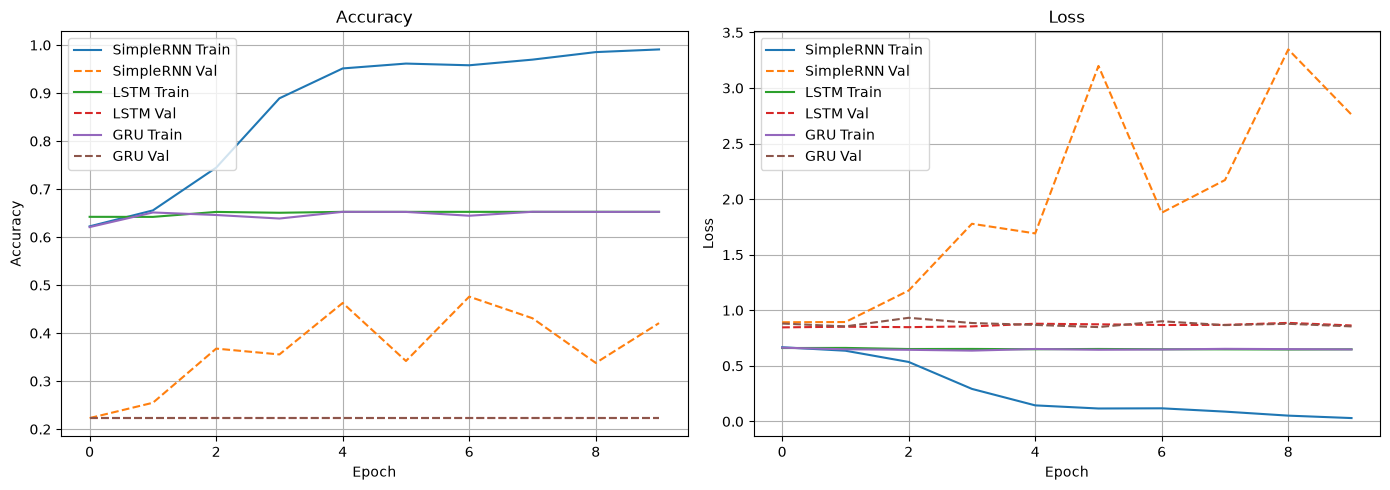

In [71]:
mat.figure(figsize=(14, 5))

mat.subplot(1, 2, 1)
for name, hist in history.items():
    mat.plot(hist["accuracy"], label=f"{name} Train")
    mat.plot(hist["val_accuracy"], label=f"{name} Val", linestyle="--")
mat.title("Accuracy")
mat.xlabel("Epoch")
mat.ylabel("Accuracy")
mat.legend()
mat.grid(True)

mat.subplot(1, 2, 2)
for name, hist in history.items():
    mat.plot(hist["loss"], label=f"{name} Train")
    mat.plot(hist["val_loss"], label=f"{name} Val", linestyle="--")
mat.title("Loss")
mat.xlabel("Epoch")
mat.ylabel("Loss")
mat.legend()
mat.grid(True)

mat.tight_layout()
mat.show()

Detailed Evaluation of Best Model

In [72]:
best_model_name = comparison.index[0]
best_model = models[best_model_name]

print(f"\nBest Model: {best_model_name}")

y_pred_prob = best_model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))


Best Model: SimpleRNN


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.41      0.56      1120
    Positive       0.54      0.92      0.68       857

    accuracy                           0.63      1977
   macro avg       0.71      0.66      0.62      1977
weighted avg       0.73      0.63      0.61      1977



Confusion Matrix

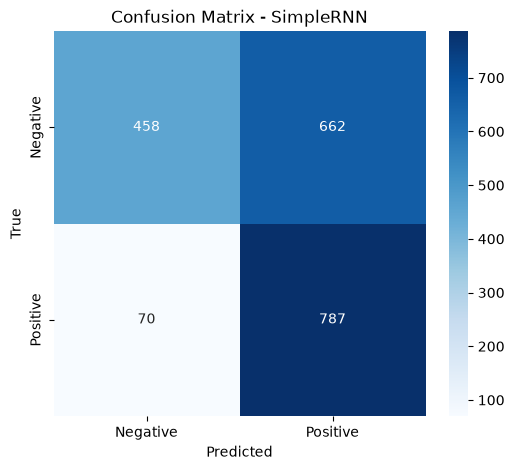

In [74]:
cm = confusion_matrix(y_test, y_pred)
mat.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"])
mat.title(f"Confusion Matrix - {best_model_name}")
mat.ylabel("True")
mat.xlabel("Predicted")
mat.show()

Save Best Model + Tokenizer

In [75]:
best_model.save(f"imdb_sentiment_{best_model_name.lower()}.h5")
print(f"\nModel saved as: imdb_sentiment_{best_model_name.lower()}.h5")

import pickle
with open("tokenizer_imdb_sentiment.pickle", "wb") as f:
    pickle.dump(tokenizer, f)
print("Tokenizer saved as: tokenizer_imdb_sentiment.pickle")

# Also save max_length
with open("max_length_imdb.pickle", "wb") as f:
    pickle.dump(max_length, f)
print("max_length saved.")


Model saved as: imdb_sentiment_simplernn.h5
Tokenizer saved as: tokenizer_imdb_sentiment.pickle
max_length saved.


Now, I will create UI from these files.